In [48]:
import pandas as pd
import pyranges as pr
import numpy as np

In [49]:
# load rmats output (SE, RI, A3SS, A5SS)
B_vs_mac_dir = "/bobross/jdearborn/public_data/ImmGen_Deep_RNAseq/rmats/B_vs_mac"

se_rmats = pd.read_csv(f"{B_vs_mac_dir}/SE.MATS.JC.txt", sep="\t")
ri_rmats = pd.read_csv(f"{B_vs_mac_dir}/RI.MATS.JC.txt", sep="\t")
a3ss_rmats = pd.read_csv(f"{B_vs_mac_dir}/A3SS.MATS.JC.txt", sep="\t")
a5ss_rmats = pd.read_csv(f"{B_vs_mac_dir}/A5SS.MATS.JC.txt", sep="\t")
mxe_rmats = pd.read_csv(f"{B_vs_mac_dir}/MXE.MATS.JC.txt", sep="\t")

In [50]:
# helper function for plots
import matplotlib.pyplot as plt

def prep_volcano_df(df):
    return (
        df.assign(
            FDR=pd.to_numeric(df["FDR"], errors="coerce"),
            IncLevelDifference=pd.to_numeric(df["IncLevelDifference"], errors="coerce")
        )
        .dropna(subset=["FDR", "IncLevelDifference", "geneSymbol"])
        .assign(logFDR=lambda d: -np.log10(d["FDR"].clip(lower=1e-300)))
    )

event_tables = {
    "SE": se_rmats,
    "RI": ri_rmats,
    "A3SS": a3ss_rmats,
    "A5SS": a5ss_rmats,
    "MXE": mxe_rmats,
}

In [51]:
# remove Arap1 events from set tables
for event_type, df in event_tables.items():
    event_tables[event_type] = df[df["geneSymbol"] != "Arap1"]

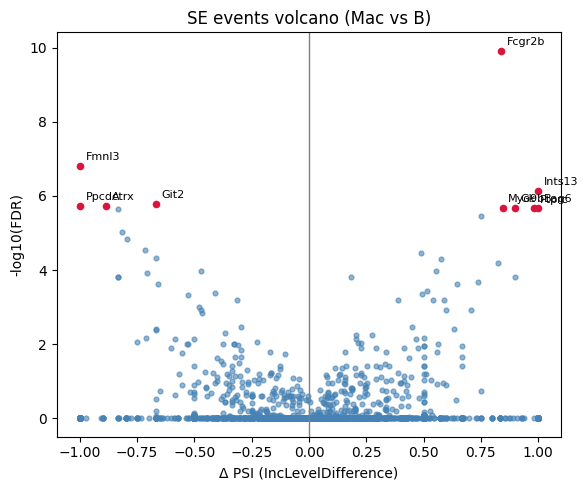

         ID                 GeneID geneSymbol    chr strand  exonStart_0base  \
495    3264  ENSMUSG00000026656.15     Fcgr2b   chr1      -        170963324   
377    2545  ENSMUSG00000023008.18      Fmnl3  chr15      -         99318917   
2886  17460  ENSMUSG00000040250.14     Ints13   chr6      -        146550086   
1684  10310  ENSMUSG00000041890.17       Git2   chr5      -        114737347   
29      335  ENSMUSG00000031229.16       Atrx   chrX      -        105911469   
2621  15922   ENSMUSG00000063849.6      Ppcdc   chr9      -         57439113   
2480  14970  ENSMUSG00000004677.17      Myo9b   chr8      +         71336875   
2870  17376  ENSMUSG00000024392.17       Bag6  chr17      +         35146756   
3291  20067  ENSMUSG00000025059.16         Gk   chrX      -         85706237   
1729  10555  ENSMUSG00000026395.16      Ptprc   chr1      -        138122455   

        exonEnd  upstreamES  upstreamEE  downstreamES  ...  IJC_SAMPLE_2  \
495   170963465   170961195   170961233    

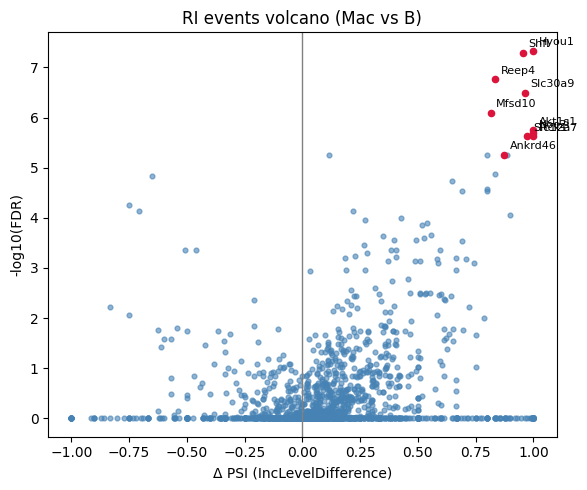

        ID                 GeneID geneSymbol    chr strand  riExonStart_0base  \
1436  3262  ENSMUSG00000032115.14      Hyou1   chr9      +           44387031   
1410  3189  ENSMUSG00000038884.14       Shfl   chr9      +           20872867   
721   1632   ENSMUSG00000033589.4      Reep4  chr14      +           70546929   
428    896  ENSMUSG00000029221.15    Slc30a9   chr5      +           67342093   
526   1172  ENSMUSG00000001082.12     Mfsd10   chr5      -           34634590   
1194  2642  ENSMUSG00000011096.17     Akt1s1   chr7      +           44853779   
1626  3689   ENSMUSG00000095567.8      Noc2l   chr4      +          156237342   
407    853  ENSMUSG00000068206.13      Pick1  chr15      +           79247264   
1768  3994   ENSMUSG00000017756.9    Slc12a7  chr13      +           73796766   
281    540   ENSMUSG00000048307.8    Ankrd46  chr15      -           36483980   

      riExonEnd  upstreamES  upstreamEE  downstreamES  ...  IJC_SAMPLE_2  \
1436   44387329    44387031    4

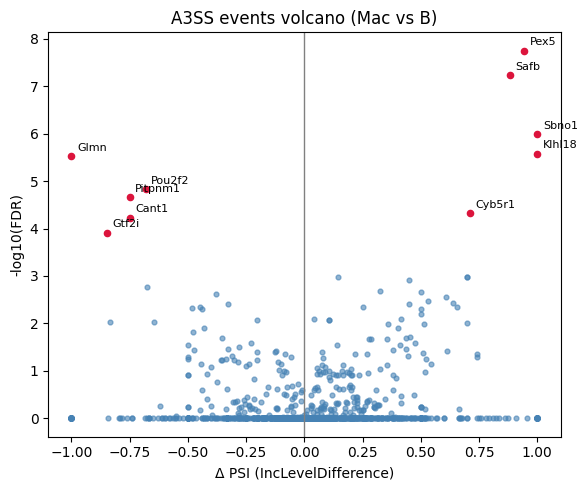

        ID                 GeneID geneSymbol    chr strand  \
308   1328  ENSMUSG00000005069.12       Pex5   chr6      -   
70     299  ENSMUSG00000071054.12       Safb  chr17      +   
970   4208  ENSMUSG00000038095.15      Sbno1   chr5      -   
1029  4469  ENSMUSG00000054792.15     Klhl18   chr9      -   
287   1222  ENSMUSG00000029276.13       Glmn   chr5      -   
1040  4528  ENSMUSG00000008496.19     Pou2f2   chr7      -   
448   1945  ENSMUSG00000024851.14    Pitpnm1  chr19      +   
843   3642  ENSMUSG00000026456.18     Cyb5r1   chr1      +   
1145  4961  ENSMUSG00000025575.14      Cant1  chr11      -   
383   1668  ENSMUSG00000060261.15      Gtf2i   chr5      -   

      longExonStart_0base  longExonEnd    shortES    shortEE  flankingES  ...  \
308             124413568    124413790  124413568  124413701   124414006  ...   
70               56601047     56601130   56601055   56601130    56600821  ...   
970             124410069    124410382  124410069  124410379   124414398  

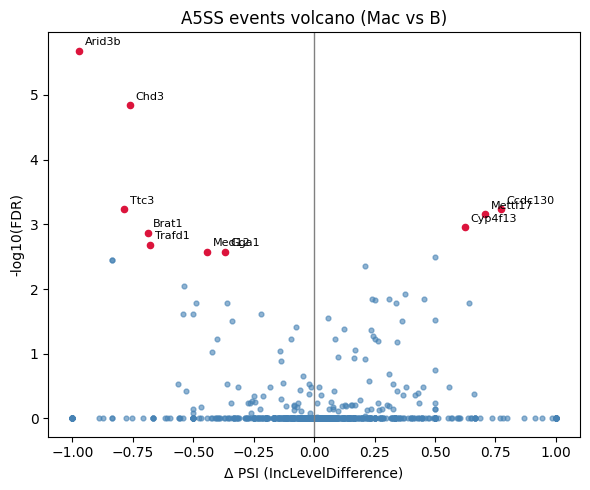

       ID                 GeneID geneSymbol    chr strand  \
603  2445  ENSMUSG00000004661.15     Arid3b   chr9      -   
317  1340  ENSMUSG00000018474.18       Chd3  chr11      -   
67    315  ENSMUSG00000040785.19       Ttc3  chr16      +   
566  2313  ENSMUSG00000004994.12    Ccdc130   chr8      -   
169   736  ENSMUSG00000004561.14    Mettl17  chr14      +   
52    230  ENSMUSG00000024055.15    Cyp4f13  chr17      -   
402  1599  ENSMUSG00000000148.17      Brat1   chr5      +   
430  1732  ENSMUSG00000042726.14     Trafd1   chr5      -   
89    411   ENSMUSG00000033128.9       Gga1  chr15      +   
359  1474  ENSMUSG00000079487.11      Med12   chrX      +   

     longExonStart_0base  longExonEnd    shortES    shortEE  flankingES  ...  \
603             57810338     57810480   57810408   57810480    57810164  ...   
317             69346571     69346813   69346617   69346813    69345470  ...   
67              94370766     94370971   94370766   94370861    94383911  ...   
566     

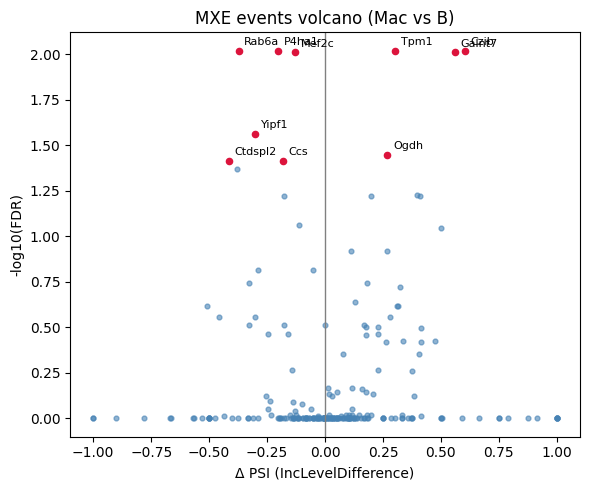

      ID                 GeneID geneSymbol    chr strand  1stExonStart_0base  \
36   132  ENSMUSG00000028608.15       Czib   chr4      +           107891464   
44   151  ENSMUSG00000030704.14      Rab6a   chr7      +           100629665   
87   277  ENSMUSG00000032366.15       Tpm1   chr9      -            67031950   
189  644  ENSMUSG00000019916.14      P4ha1  chr10      +            59354339   
53   195  ENSMUSG00000031608.13     Galnt7   chr8      -            57542511   
69   230  ENSMUSG00000005583.16      Mef2c  chr13      +            83625264   
62   211  ENSMUSG00000057375.13      Yipf1   chr4      +           107318941   
30   107  ENSMUSG00000020456.17       Ogdh  chr11      +             6316764   
4     31   ENSMUSG00000034108.6        Ccs  chr19      -             4833340   
130  430  ENSMUSG00000033411.16    Ctdspl2   chr2      +           121978891   

     1stExonEnd  2ndExonStart_0base  2ndExonEnd  upstreamES  ...  \
36    107891521           107891954   107892036   1

In [52]:
# iterate through event types and create volcano plots

from adjustText import adjust_text

for event, table in event_tables.items():
    plot_df = prep_volcano_df(table)
    if plot_df.empty:
        continue

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(plot_df["IncLevelDifference"], plot_df["logFDR"], s=12, alpha=0.6, color="steelblue")
    ax.axvline(0, color="gray", lw=1)
    ax.set_xlabel("Δ PSI (IncLevelDifference)")
    ax.set_ylabel("-log10(FDR)")
    ax.set_title(f"{event} events volcano (Mac vs B)")

    top_hits = (
        pd.concat(
            [
                plot_df.nsmallest(10, "FDR"),
                plot_df[plot_df["geneSymbol"] == "Ptprc"],
            ]
        )
        .drop_duplicates(subset="geneSymbol")
    )
    for _, row in top_hits.iterrows():
        ax.scatter(row["IncLevelDifference"], row["logFDR"], color="crimson", s=20)
        ax.annotate(row["geneSymbol"], (row["IncLevelDifference"], row["logFDR"]),
                    xytext=(4, 4), textcoords="offset points", fontsize=8)

    plt.tight_layout()
    plt.show()
    print(top_hits)

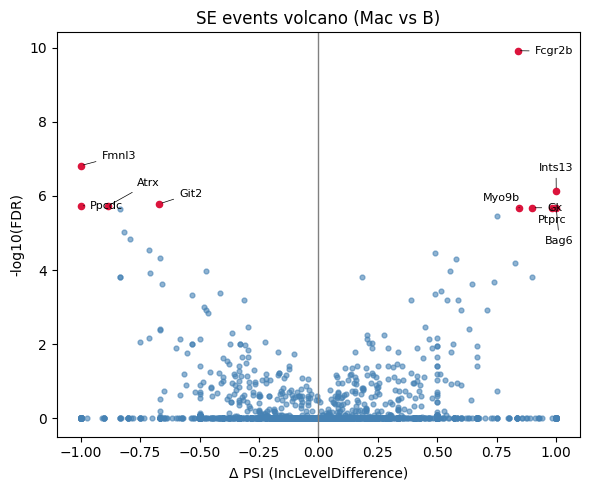

         ID                 GeneID geneSymbol    chr strand  exonStart_0base  \
495    3264  ENSMUSG00000026656.15     Fcgr2b   chr1      -        170963324   
377    2545  ENSMUSG00000023008.18      Fmnl3  chr15      -         99318917   
2886  17460  ENSMUSG00000040250.14     Ints13   chr6      -        146550086   
1684  10310  ENSMUSG00000041890.17       Git2   chr5      -        114737347   
29      335  ENSMUSG00000031229.16       Atrx   chrX      -        105911469   
2621  15922   ENSMUSG00000063849.6      Ppcdc   chr9      -         57439113   
2480  14970  ENSMUSG00000004677.17      Myo9b   chr8      +         71336875   
2870  17376  ENSMUSG00000024392.17       Bag6  chr17      +         35146756   
3291  20067  ENSMUSG00000025059.16         Gk   chrX      -         85706237   
1729  10555  ENSMUSG00000026395.16      Ptprc   chr1      -        138122455   

        exonEnd  upstreamES  upstreamEE  downstreamES  ...  IJC_SAMPLE_2  \
495   170963465   170961195   170961233    

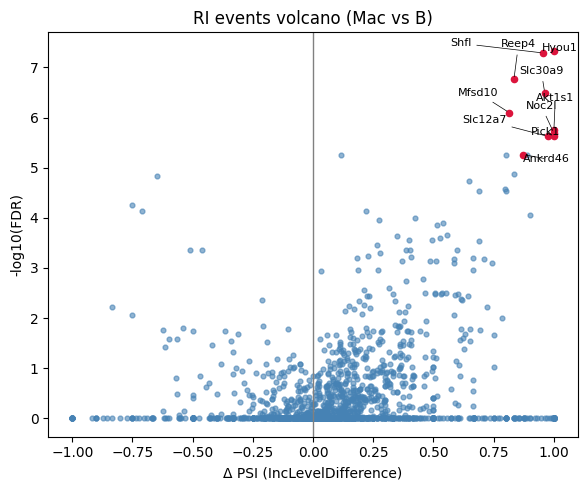

        ID                 GeneID geneSymbol    chr strand  riExonStart_0base  \
1436  3262  ENSMUSG00000032115.14      Hyou1   chr9      +           44387031   
1410  3189  ENSMUSG00000038884.14       Shfl   chr9      +           20872867   
721   1632   ENSMUSG00000033589.4      Reep4  chr14      +           70546929   
428    896  ENSMUSG00000029221.15    Slc30a9   chr5      +           67342093   
526   1172  ENSMUSG00000001082.12     Mfsd10   chr5      -           34634590   
1194  2642  ENSMUSG00000011096.17     Akt1s1   chr7      +           44853779   
1626  3689   ENSMUSG00000095567.8      Noc2l   chr4      +          156237342   
407    853  ENSMUSG00000068206.13      Pick1  chr15      +           79247264   
1768  3994   ENSMUSG00000017756.9    Slc12a7  chr13      +           73796766   
281    540   ENSMUSG00000048307.8    Ankrd46  chr15      -           36483980   

      riExonEnd  upstreamES  upstreamEE  downstreamES  ...  IJC_SAMPLE_2  \
1436   44387329    44387031    4

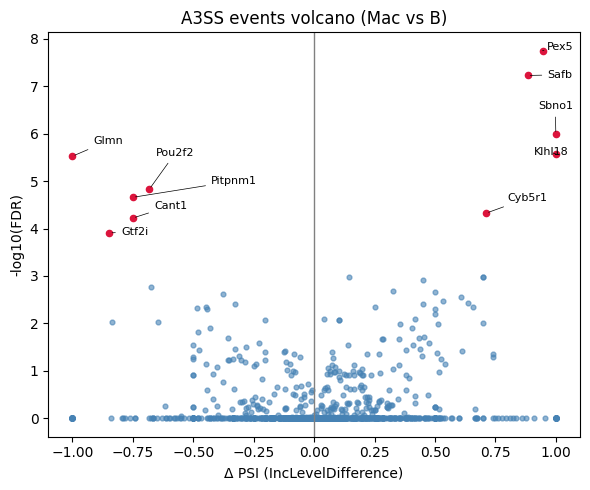

        ID                 GeneID geneSymbol    chr strand  \
308   1328  ENSMUSG00000005069.12       Pex5   chr6      -   
70     299  ENSMUSG00000071054.12       Safb  chr17      +   
970   4208  ENSMUSG00000038095.15      Sbno1   chr5      -   
1029  4469  ENSMUSG00000054792.15     Klhl18   chr9      -   
287   1222  ENSMUSG00000029276.13       Glmn   chr5      -   
1040  4528  ENSMUSG00000008496.19     Pou2f2   chr7      -   
448   1945  ENSMUSG00000024851.14    Pitpnm1  chr19      +   
843   3642  ENSMUSG00000026456.18     Cyb5r1   chr1      +   
1145  4961  ENSMUSG00000025575.14      Cant1  chr11      -   
383   1668  ENSMUSG00000060261.15      Gtf2i   chr5      -   

      longExonStart_0base  longExonEnd    shortES    shortEE  flankingES  ...  \
308             124413568    124413790  124413568  124413701   124414006  ...   
70               56601047     56601130   56601055   56601130    56600821  ...   
970             124410069    124410382  124410069  124410379   124414398  

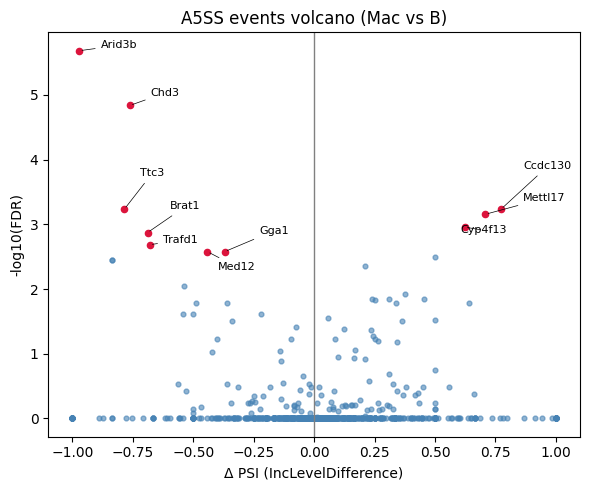

       ID                 GeneID geneSymbol    chr strand  \
603  2445  ENSMUSG00000004661.15     Arid3b   chr9      -   
317  1340  ENSMUSG00000018474.18       Chd3  chr11      -   
67    315  ENSMUSG00000040785.19       Ttc3  chr16      +   
566  2313  ENSMUSG00000004994.12    Ccdc130   chr8      -   
169   736  ENSMUSG00000004561.14    Mettl17  chr14      +   
52    230  ENSMUSG00000024055.15    Cyp4f13  chr17      -   
402  1599  ENSMUSG00000000148.17      Brat1   chr5      +   
430  1732  ENSMUSG00000042726.14     Trafd1   chr5      -   
89    411   ENSMUSG00000033128.9       Gga1  chr15      +   
359  1474  ENSMUSG00000079487.11      Med12   chrX      +   

     longExonStart_0base  longExonEnd    shortES    shortEE  flankingES  ...  \
603             57810338     57810480   57810408   57810480    57810164  ...   
317             69346571     69346813   69346617   69346813    69345470  ...   
67              94370766     94370971   94370766   94370861    94383911  ...   
566     

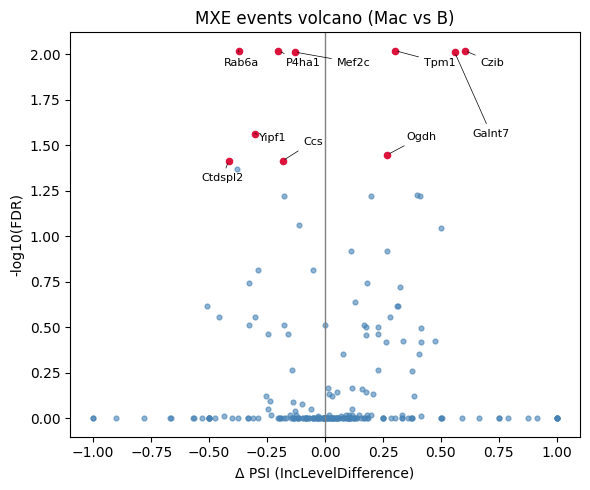

      ID                 GeneID geneSymbol    chr strand  1stExonStart_0base  \
36   132  ENSMUSG00000028608.15       Czib   chr4      +           107891464   
44   151  ENSMUSG00000030704.14      Rab6a   chr7      +           100629665   
87   277  ENSMUSG00000032366.15       Tpm1   chr9      -            67031950   
189  644  ENSMUSG00000019916.14      P4ha1  chr10      +            59354339   
53   195  ENSMUSG00000031608.13     Galnt7   chr8      -            57542511   
69   230  ENSMUSG00000005583.16      Mef2c  chr13      +            83625264   
62   211  ENSMUSG00000057375.13      Yipf1   chr4      +           107318941   
30   107  ENSMUSG00000020456.17       Ogdh  chr11      +             6316764   
4     31   ENSMUSG00000034108.6        Ccs  chr19      -             4833340   
130  430  ENSMUSG00000033411.16    Ctdspl2   chr2      +           121978891   

     1stExonEnd  2ndExonStart_0base  2ndExonEnd  upstreamES  ...  \
36    107891521           107891954   107892036   1

In [53]:
# iterate through event types and create volcano plots

from adjustText import adjust_text

for event, table in event_tables.items():
    plot_df = prep_volcano_df(table)
    if plot_df.empty:
        continue

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(plot_df["IncLevelDifference"], plot_df["logFDR"], s=12, alpha=0.6, color="steelblue")
    ax.axvline(0, color="gray", lw=1)
    ax.set_xlabel("Δ PSI (IncLevelDifference)")
    ax.set_ylabel("-log10(FDR)")
    ax.set_title(f"{event} events volcano (Mac vs B)")

    top_hits = (
        pd.concat(
            [
                plot_df.nsmallest(10, "FDR"),
                plot_df[plot_df["geneSymbol"] == "Ptprc"],
            ]
        )
        .drop_duplicates(subset="geneSymbol")
    )
    texts = []
    for _, row in top_hits.iterrows():
        ax.scatter(row["IncLevelDifference"], row["logFDR"], color="crimson", s=20)
        texts.append(
            ax.annotate(
                row["geneSymbol"],
                xy=(row["IncLevelDifference"], row["logFDR"]),
                xytext=(row["IncLevelDifference"] + 0.05, row["logFDR"] + 0.3),
                textcoords="data",
                fontsize=8,
                arrowprops=dict(arrowstyle="-", color="black", lw=0.5),
            )
        )

    adjust_text(
        texts,
        ax=ax,
        force_points=0.05,
        force_text=0.05,
        expand_points=(1.02, 1.02),
        expand_text=(1.02, 1.02),
        only_move={"points": "y", "text": "xy"},
    )

    plt.tight_layout()
    plt.show()
    print(top_hits)

In [54]:
# load rmats output (SE, RI, A3SS, A5SS)
B_vs_T_dir = "/bobross/jdearborn/public_data/ImmGen_Deep_RNAseq/rmats/B_vs_T"

se_rmats = pd.read_csv(f"{B_vs_T_dir}/SE.MATS.JC.txt", sep="\t")
ri_rmats = pd.read_csv(f"{B_vs_T_dir}/RI.MATS.JC.txt", sep="\t")
a3ss_rmats = pd.read_csv(f"{B_vs_T_dir}/A3SS.MATS.JC.txt", sep="\t")
a5ss_rmats = pd.read_csv(f"{B_vs_T_dir}/A5SS.MATS.JC.txt", sep="\t")
mxe_rmats = pd.read_csv(f"{B_vs_T_dir}/MXE.MATS.JC.txt", sep="\t")

In [55]:
event_tables = {
    "SE": se_rmats,
    "RI": ri_rmats,
    "A3SS": a3ss_rmats,
    "A5SS": a5ss_rmats,
    "MXE": mxe_rmats,
}

1 [ 0.79045755 -0.11724246]
2 [ 0.27568954 -0.0036585 ]


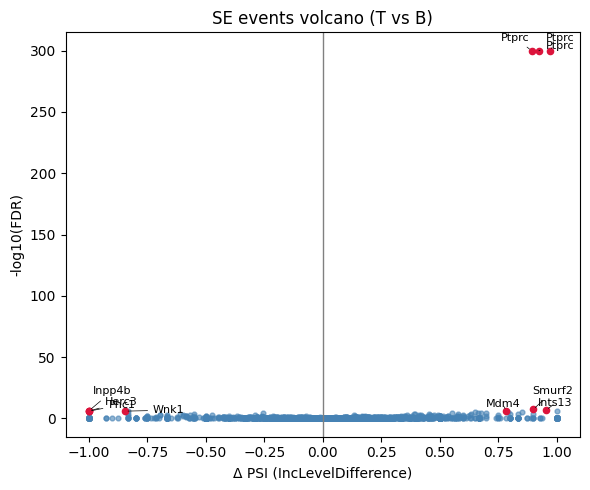

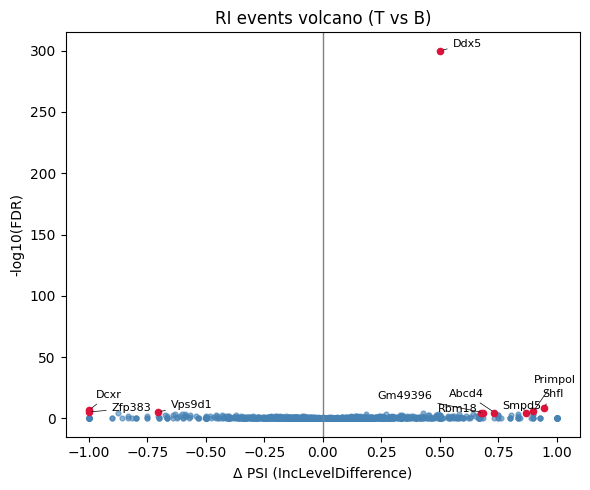

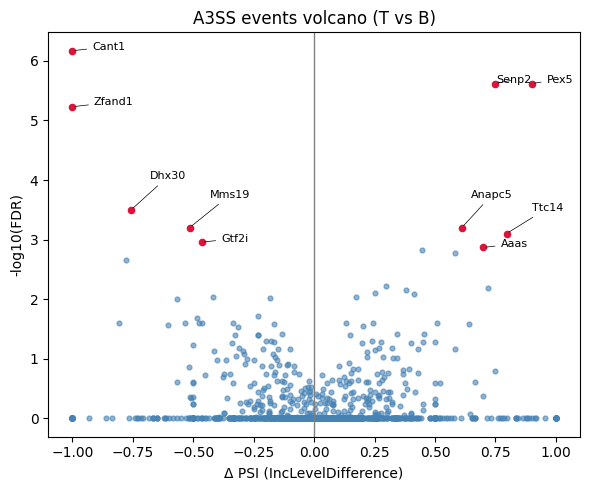

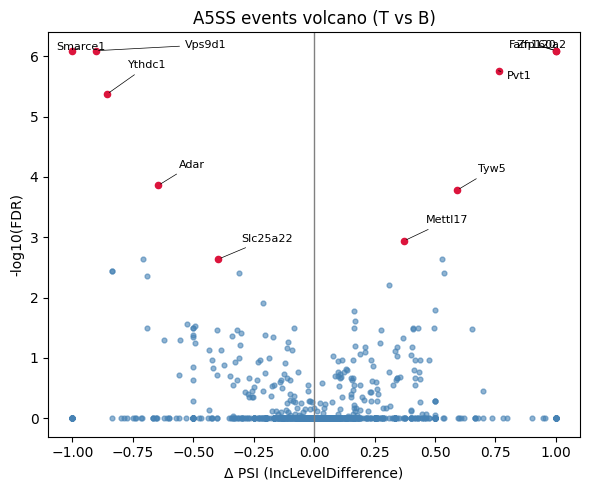

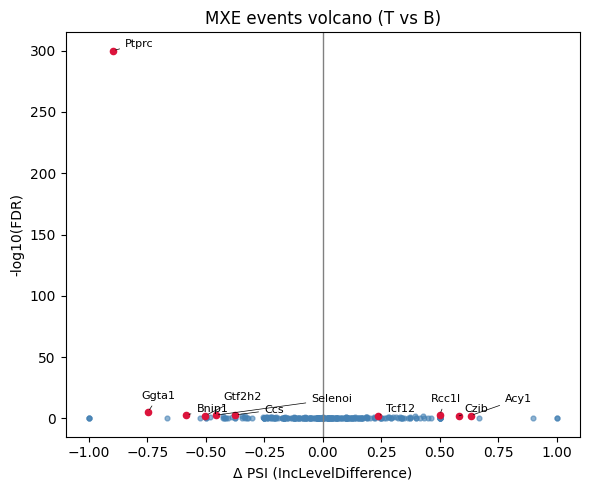

In [56]:
for event, table in event_tables.items():
    plot_df = prep_volcano_df(table)
    if plot_df.empty:
        continue

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(plot_df["IncLevelDifference"], plot_df["logFDR"], s=12, alpha=0.6, color="steelblue")
    ax.axvline(0, color="gray", lw=1)
    ax.set_xlabel("Δ PSI (IncLevelDifference)")
    ax.set_ylabel("-log10(FDR)")
    ax.set_title(f"{event} events volcano (T vs B)")

    top_hits = plot_df.nsmallest(10, "FDR")
    texts = []
    for _, row in top_hits.iterrows():
        ax.scatter(row["IncLevelDifference"], row["logFDR"], color="crimson", s=20)
        texts.append(
            ax.annotate(
                row["geneSymbol"],
                xy=(row["IncLevelDifference"], row["logFDR"]),
                xytext=(row["IncLevelDifference"] + 0.05, row["logFDR"] + 0.3),
                textcoords="data",
                fontsize=8,
                arrowprops=dict(arrowstyle="-", color="black", lw=0.5),
            )
        )

    adjust_text(
        texts,
        ax=ax,
        force_points=0.05,
        force_text=0.05,
        expand_points=(1.02, 1.02),
        expand_text=(1.02, 1.02),
        only_move={"points": "y", "text": "xy"},
    )

    plt.tight_layout()
    plt.show()

### rMATS solo runs
Global eval based on inc levels

In [57]:
# load each cell type JC file to a pd DataFrame
cell_types = ["B", "Macrophage", "T"]
rmats_data = {}
for cell_type in cell_types:
    dir_path = f"/bobross/jdearborn/public_data/ImmGen_Deep_RNAseq/rmats/{cell_type}_only"
    se_rmats = pd.read_csv(f"{dir_path}/SE.MATS.JC.txt", sep="\t")
    ri_rmats = pd.read_csv(f"{dir_path}/RI.MATS.JC.txt", sep="\t")
    a3ss_rmats = pd.read_csv(f"{dir_path}/A3SS.MATS.JC.txt", sep="\t")
    a5ss_rmats = pd.read_csv(f"{dir_path}/A5SS.MATS.JC.txt", sep="\t")
    rmats_data[cell_type] = {
        "SE": se_rmats,
        "RI": ri_rmats,
        "A3SS": a3ss_rmats,
        "A5SS": a5ss_rmats,
    }

In [58]:
# create an average Inc level column across each cell type for SE event type that averages IncLevel1 and IncLevel2
se_avg_inc_levels = {}
for cell_type, tables in rmats_data.items():
    se_table = tables["SE"]
    se_table = se_table.assign(
        AvgIncLevel=lambda d: (pd.to_numeric(d["IncLevel1"], errors="coerce") + pd.to_numeric(d["IncLevel2"], errors="coerce")) / 2
    )
    se_avg_inc_levels[cell_type] = se_table[["ID", "AvgIncLevel"]]

In [59]:
# inspect the average inclusion levels
for cell_type, df in se_avg_inc_levels.items():
    print(f"Cell Type: {cell_type}")
    print(df.head())

Cell Type: B
   ID  AvgIncLevel
0   0          NaN
1   1          NaN
2   2          NaN
3   3          NaN
4   4          NaN
Cell Type: Macrophage
   ID  AvgIncLevel
0   0          NaN
1   1          NaN
2   2          NaN
3   3          NaN
4   4          NaN
Cell Type: T
   ID  AvgIncLevel
0   0          NaN
1   1          NaN
2   2          NaN
3   3          NaN
4   4          NaN


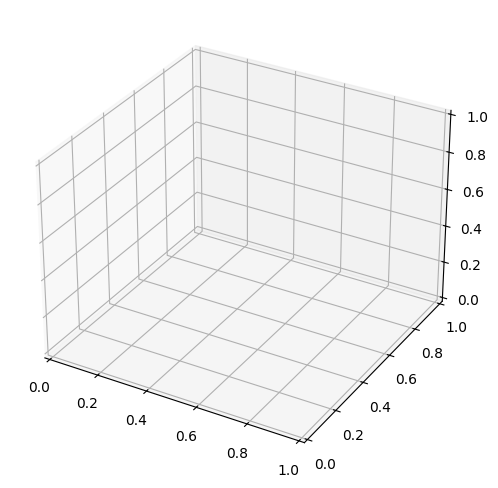

In [60]:
# for each event type, create a 3-D plot comparing AvgIncLevel across cell types. each axis should be a cell type
# subset the df for events present in all three cell types
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

merged_inc = (
    se_avg_inc_levels["B"]
    .merge(se_avg_inc_levels["Macrophage"], on="ID", suffixes=("_B", "_Mac"))
    .merge(se_avg_inc_levels["T"], on="ID")
    .rename(columns={"AvgIncLevel": "AvgIncLevel_T"})
    .dropna()
)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(
    merged_inc["AvgIncLevel_B"],
    merged_inc["AvgIncLevel_Mac"],
    merged_inc["AvgIncLevel_T"],
    c="teal",
    alpha=0.7,
    s=12,
)